# Importing train/test datasets and building X, y

In [3]:
import pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.metrics import (mean_squared_error, mean_absolute_error, root_mean_squared_error,
                             r2_score)

SPLITS = ['Butina', 'Family']
TARGET = 'Surface_tension'

with open(r"Data and variables/GC_variables.pkl", "rb") as f:
    group_cols = pickle.load(f)["group_cols"]          # group counts + T

# Same logic used in 02_ChemicalDataset to build each train/test split:
# StratifiedGroupKFold with groups=ChemID, stratified by Butina cluster or by chemical Family
STRAT_COL = {'Butina': 'cluster_id', 'Family': 'Family'}
GROUP_COL = 'ChemID'
N_CV = 5


def make_cv(train, split, n_splits=N_CV):
    """Explicit CV folds for the training set that preserve how the outer split was built:
    a compound (ChemID) never appears in two folds, and each fold keeps a similar cluster/family mix."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')     # singleton clusters/families can't be stratified
        folds = list(sgkf.split(train, y=train[STRAT_COL[split]], groups=train[GROUP_COL]))
    for tr, va in folds:
        assert set(train.iloc[tr][GROUP_COL]).isdisjoint(train.iloc[va][GROUP_COL])
    return folds


# data[split] -> X_train, y_train, X_test, y_test (group-contribution features) and CV folds
data = {}
for s in SPLITS:
    train = pd.read_pickle(rf'Data and variables/train_{s}.pkl')
    test = pd.read_pickle(rf'Data and variables/test_{s}.pkl')
    data[s] = dict(X_train=train[group_cols], y_train=train[TARGET],
                   X_test=test[group_cols], y_test=test[TARGET],
                   test_meta=test[['ChemID', 'Family', 'TC']],   # TC: post-hoc check only, never a model feature
                   cv=make_cv(train, s))

# metrics tables (one per split) and fitted models
COLUMNS = ['description', 'algorithm', 'MSE', 'RMSE', 'MAE', 'SD_error', 'NRMSE_%', 'WAPE_%', 'r2_score']
metrics_paths = {s: rf'Data and variables/metrics_{s}.pkl' for s in SPLITS}
metrics = {}
for s in SPLITS:
    try:
        metrics[s] = pd.read_pickle(metrics_paths[s])
    except FileNotFoundError:
        metrics[s] = pd.DataFrame(columns=COLUMNS)

models = {}      # (algorithm, split) -> fitted estimator
cv_folds = {}    # (algorithm, split) -> per-fold validation metrics of the best candidate

for s in SPLITS:
    print(s, data[s]['X_train'].shape, data[s]['X_test'].shape)

Butina (17058, 30) (8530, 30)
Family (17101, 30) (8487, 30)


# Helper functions

In [9]:
def get_metrics(model, X_test, y_test, metrics, path, model_desc, algorithm):
    """Evaluate on the test set, add/replace the row in `metrics`, save it and return it."""
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred
    rmse = root_mean_squared_error(y_test, y_pred)

    row = pd.DataFrame([{
        'description': model_desc,
        'algorithm': algorithm,
        'MSE': mean_squared_error(y_test, y_pred),
        'RMSE': rmse,
        'MAE': mean_absolute_error(y_test, y_pred),
        'SD_error': np.std(residuals, ddof=1),
        'NRMSE_%': rmse / np.mean(y_test) * 100,      # % of mean experimental value
        'WAPE_%': residuals.abs().sum() / y_test.abs().sum() * 100,  # weighted (not pointwise) absolute % error
        'r2_score': r2_score(y_test, y_pred),
    }])

    # re-running a model replaces its previous row
    keep = ~((metrics['description'] == model_desc) & (metrics['algorithm'] == algorithm))
    metrics = pd.concat([metrics[keep], row], ignore_index=True)
    metrics.to_pickle(path)
    return metrics


CV_SCORING = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error', 'r2': 'r2',
              'MSE': 'neg_mean_squared_error'}


def get_best(reg, params, X, y, cv=5, n_iter=50, n_jobs=-1):
    """Randomized search selecting on MSE. Returns (best estimator, per-fold metrics of the best candidate)."""
    rcv = RandomizedSearchCV(reg, params, n_iter=n_iter, cv=cv, scoring=CV_SCORING, refit='MSE',
                             random_state=42, n_jobs=n_jobs)
    rcv.fit(X, y)
    res, i = rcv.cv_results_, rcv.best_index_
    n_folds = rcv.n_splits_
    folds = pd.DataFrame({
        'fold': range(1, n_folds + 1),
        'n_val': [len(v) for _, v in (cv if not isinstance(cv, int) else [])] or np.nan,
        'RMSE': [-res[f'split{k}_test_RMSE'][i] for k in range(n_folds)],
        'MAE': [-res[f'split{k}_test_MAE'][i] for k in range(n_folds)],
        'r2': [res[f'split{k}_test_r2'][i] for k in range(n_folds)],
    }).set_index('fold')
    print('best params:', rcv.best_params_)
    return rcv.best_estimator_, folds


def show_folds(folds, title):
    summary = pd.DataFrame({'mean': folds[['RMSE', 'MAE', 'r2']].mean(), 'std': folds[['RMSE', 'MAE', 'r2']].std()}).T
    print(f'CV metrics per fold - {title}')
    display(pd.concat([folds, summary]).round(3))


def plot_actual_vs_predicted(model, X_test, y_test, title):
    y_pred = model.predict(X_test)
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, y_pred, alpha=0.5)
    mn, mx = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    plt.plot([mn, mx], [mn, mx], 'r--')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.text(0.05, 0.95, f'{title}\nR² = {r2_score(y_test, y_pred):.3f}',
             transform=plt.gca().transAxes, va='top', bbox=dict(facecolor='white', alpha=0.8))
    plt.show()


def record(model, algorithm, split, desc='GC'):
    d = data[split]
    metrics[split] = get_metrics(model, d['X_test'], d['y_test'], metrics[split],
                                 metrics_paths[split], desc, algorithm)
    models[(algorithm, split)] = model


def fit_all(algorithm, reg, params, n_iter=50, plot=True, n_jobs=-1):
    """Tune `reg` with randomized CV (grouped by ChemID, stratified like the split) on each split, evaluate on its test set and store the results."""
    for s in SPLITS:
        print(f'--- {algorithm} | {s} split ---')
        d = data[s]
        best, folds = get_best(reg, params, d['X_train'], d['y_train'], cv=d['cv'], n_iter=n_iter, n_jobs=n_jobs)
        cv_folds[(algorithm, s)] = folds
        show_folds(folds, f'{algorithm} ({s})')
        record(best, algorithm, s)
        if plot:
            plot_actual_vs_predicted(best, d['X_test'], d['y_test'], f'{algorithm} ({s})')


def scaled(est):
    """Scale X (fit on training folds only) and standardize y; predictions return in original units."""
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), est),
                                      transformer=StandardScaler())


def plot_coefs(algorithm, split, title):
    model = models[(algorithm, split)]
    est = model[-1] if isinstance(model, Pipeline) else model
    coef = pd.Series(est.coef_, index=data[split]['X_train'].columns).sort_values(key=np.abs)
    plt.figure(figsize=(8, 8))
    plt.barh(coef.index, coef.values)
    plt.axvline(0, color='black')
    plt.xlabel('Standardized coefficient')
    plt.title(f'{title} ({split})')
    plt.show()


def plot_training_curves(algorithm, split, title):
    """Loss and R2 per epoch for a fitted TorchMLPRegressor, from its training history."""
    model = models[(algorithm, split)]
    net = model.regressor_[-1] if hasattr(model, 'regressor_') else model[-1]
    h = net.history_

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['epoch'], h['train_loss'], label='train')
    axes[0].plot(h['epoch'], h['val_loss'], label='val')
    axes[0].axvline(net.best_epoch_, color='gray', linestyle='--', label='best epoch')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE loss (standardized y)')
    axes[0].set_title(f'Loss vs Epoch - {title}')
    axes[0].legend()

    axes[1].plot(h['epoch'], h['train_r2'], label='train')
    axes[1].plot(h['epoch'], h['val_r2'], label='val')
    axes[1].axvline(net.best_epoch_, color='gray', linestyle='--', label='best epoch')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('R\u00b2')
    axes[1].set_title(f'R\u00b2 vs Epoch - {title}')
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def diagnose_errors(algorithm, split, worst_n=15):
    """Break down a fitted model's test-set error: residual vs T, residual vs actual value,
    per-Family NRMSE (worst first), and the single worst individual predictions. Use this to find
    where an aggregate error figure (e.g. a high NRMSE_%) is actually coming from."""
    d = data[split]
    model = models[(algorithm, split)]
    y_test, y_pred = d['y_test'], model.predict(d['X_test'])
    residuals = y_test - y_pred
    title = f'{algorithm} ({split})'

    detail = pd.DataFrame({
        'ChemID': d['test_meta']['ChemID'].values,
        'Family': d['test_meta']['Family'].values,
        'T': d['X_test']['T'].values,
        'actual': y_test.values,
        'predicted': y_pred,
        'residual': residuals.values,
    })
    detail['abs_residual'] = detail['residual'].abs()
    detail['abs_pct_error'] = detail['abs_residual'] / detail['actual'].abs() * 100

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(detail['T'], detail['residual'], alpha=0.4)
    axes[0].axhline(0, color='black', lw=0.8)
    axes[0].set_xlabel('T')
    axes[0].set_ylabel('Residual (actual - predicted)')
    axes[0].set_title(f'Residual vs T - {title}')

    axes[1].scatter(detail['actual'], detail['residual'], alpha=0.4)
    axes[1].axhline(0, color='black', lw=0.8)
    axes[1].set_xlabel('Actual Surface_tension')
    axes[1].set_ylabel('Residual')
    axes[1].set_title(f'Residual vs actual value - {title}')
    plt.tight_layout()
    plt.show()

    by_family = detail.groupby('Family').agg(
        n=('residual', 'size'),
        RMSE=('residual', lambda r: np.sqrt((r ** 2).mean())),
        MAE=('abs_residual', 'mean'),
        mean_actual=('actual', 'mean'),
    )
    by_family['NRMSE_%'] = by_family['RMSE'] / by_family['mean_actual'] * 100
    by_family['WAPE_%'] = by_family['MAE'] / by_family['mean_actual'] * 100
    by_family = by_family.sort_values('NRMSE_%', ascending=False)
    print(f'Error by Family (worst first) - {title}')
    display(by_family.round(3))

    print(f'{worst_n} worst predictions by absolute error - {title}')
    display(detail.sort_values('abs_pct_error', ascending=False).head(worst_n).round(3))

    return detail


def check_tc_violations(algorithm, split, tr_thresholds=(0.90, 0.95, 0.98, 0.99), zero_tol=2.0, worst_n=15):
    """Physical sanity check on the TEST set only: Surface_tension must go to ~0 as T approaches the
    critical temperature TC. TC/Tr are never used as model inputs - they're pulled in here purely to
    audit predictions. A "violation" is a near-TC test row where the model still predicts a
    non-negligible value (> zero_tol mN/m). Reports counts at several T/TC cutoffs plus the worst
    offenders, since "near TC" has no single correct definition."""
    d = data[split]
    model = models[(algorithm, split)]
    meta = d['test_meta']
    y_pred = model.predict(d['X_test'])
    title = f'{algorithm} ({split})'

    detail = pd.DataFrame({
        'ChemID': meta['ChemID'].values,
        'Family': meta['Family'].values,
        'T': d['X_test']['T'].values,
        'TC': meta['TC'].values,
        'actual': d['y_test'].values,
        'predicted': y_pred,
    })
    detail['Tr'] = detail['T'] / detail['TC']

    summary = pd.DataFrame([
        {
            'T/TC >=': thr,
            'n_rows': int((detail['Tr'] >= thr).sum()),
            'n_violations': int(((detail['Tr'] >= thr) & (detail['predicted'] > zero_tol)).sum()),
        }
        for thr in tr_thresholds
    ])
    print(f'Critical-point violations (predicted Surface_tension > {zero_tol} mN/m near TC) - {title}')
    display(summary)

    near_tc = detail[detail['Tr'] >= min(tr_thresholds)]
    worst = near_tc[near_tc['predicted'] > zero_tol].sort_values('Tr', ascending=False)
    if len(worst):
        print(f'{min(len(worst), worst_n)} worst violations (closest to TC, by T/TC) - {title}')
        display(worst.head(worst_n).round(3))
    else:
        print(f'No violations found at the loosest threshold tested (T/TC >= {min(tr_thresholds)}).')

    return detail


def plot_importance(algorithm, split, top=20):
    model = models[(algorithm, split)]
    imp = pd.Series(model.feature_importances_, index=data[split]['X_train'].columns).nlargest(top)
    plt.figure(figsize=(8, 6))
    plt.barh(imp.index[::-1], imp.values[::-1])
    plt.xlabel('Importance')
    plt.title(f'{algorithm} feature importance ({split})')
    plt.show()

# Models

Models that depend on feature scale (Linear, Ridge, SVR, GPR, MLP) are wrapped in a `Pipeline` with a `StandardScaler`, so the scaler is fit on the training folds only (no leakage inside the CV). SVR and MLP also standardize `y`. Tree-based models are scale-invariant and are used without scaling.

### Linear Regression

--- LinearRegression | Butina split ---


c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 4 is smaller than n_iter=50. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params: {'linearregression__positive': False, 'linearregression__fit_intercept': True}
CV metrics per fold - LinearRegression (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.489,3.349,0.819
2,3410.0,4.215,3.082,0.841
3,3419.0,8.745,4.371,0.414
4,3410.0,8.535,4.530,0.595
5,3409.0,6.671,4.242,0.685
mean,NaN,6.531,3.915,0.671
std,NaN,2.149,0.653,0.175


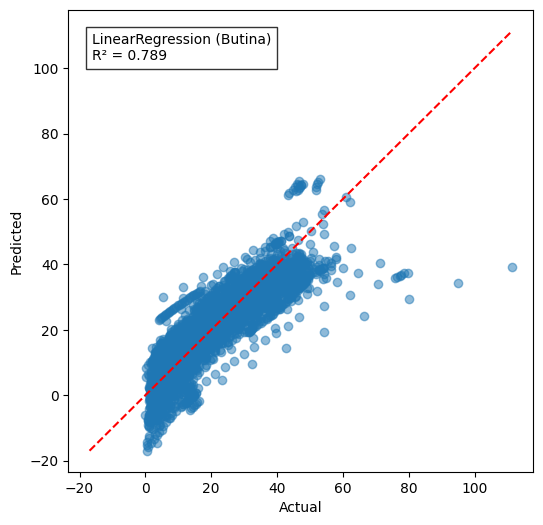

--- LinearRegression | Family split ---


c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 4 is smaller than n_iter=50. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params: {'linearregression__positive': False, 'linearregression__fit_intercept': True}
CV metrics per fold - LinearRegression (Family)


,n_val,RMSE,MAE,r2
1,3426.0,9.199,4.888,0.563
2,3421.0,5.450,3.872,0.757
3,3426.0,5.140,3.654,0.775
4,3410.0,5.326,3.885,0.762
5,3418.0,5.998,3.763,0.750
mean,NaN,6.222,4.012,0.721
std,NaN,1.694,0.498,0.089


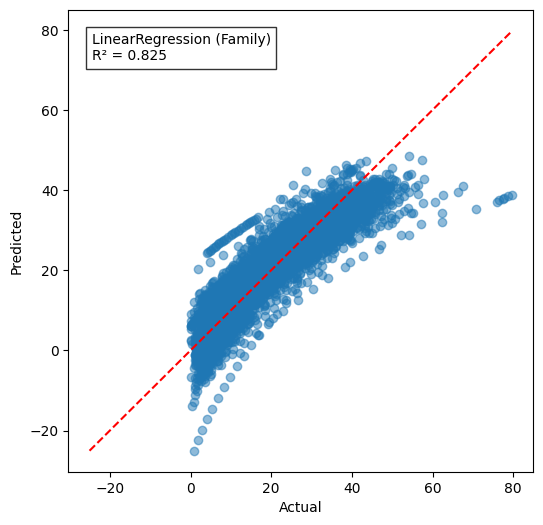

In [12]:
from sklearn.linear_model import LinearRegression

reg = make_pipeline(StandardScaler(), LinearRegression())
params = {
    'linearregression__fit_intercept': [True, False],
    'linearregression__positive': [True, False],
}
fit_all('LinearRegression', reg, params)

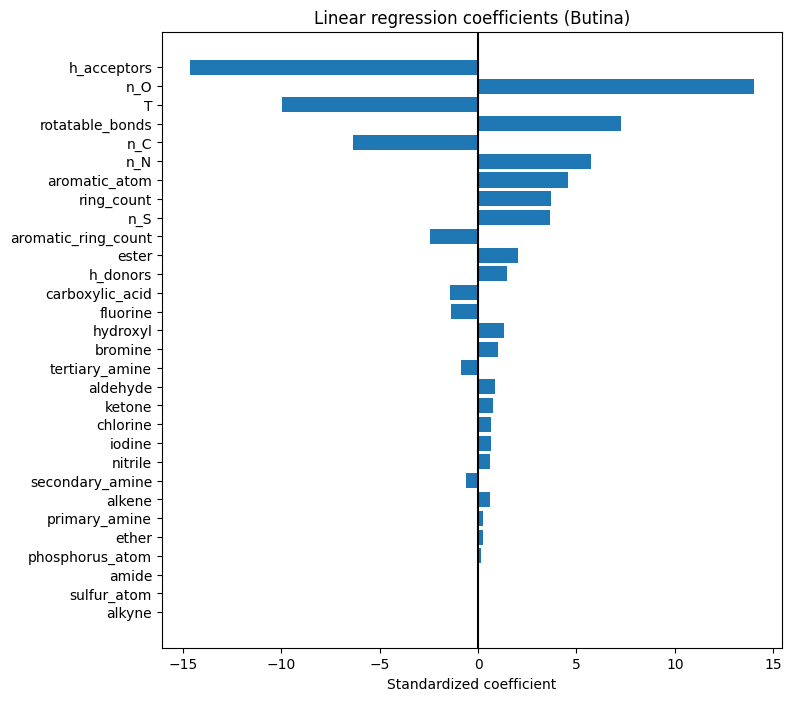

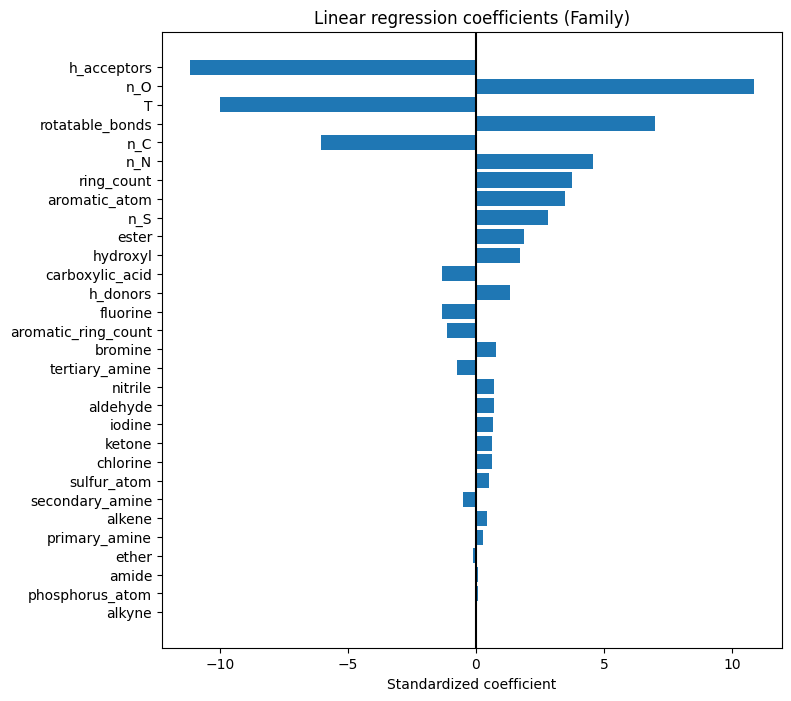

In [13]:
for s in SPLITS:
    plot_coefs('LinearRegression', s, 'Linear regression coefficients')

### Ridge Regression

--- Ridge | Butina split ---
best params: {'ridge__alpha': np.float64(584.8333713948902), 'ridge__fit_intercept': True}
CV metrics per fold - Ridge (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.363,3.319,0.829
2,3410.0,4.544,3.295,0.815
3,3419.0,5.523,3.918,0.766
4,3410.0,9.357,4.730,0.513
5,3409.0,7.132,4.366,0.640
mean,NaN,6.184,3.926,0.713
std,NaN,2.086,0.634,0.134


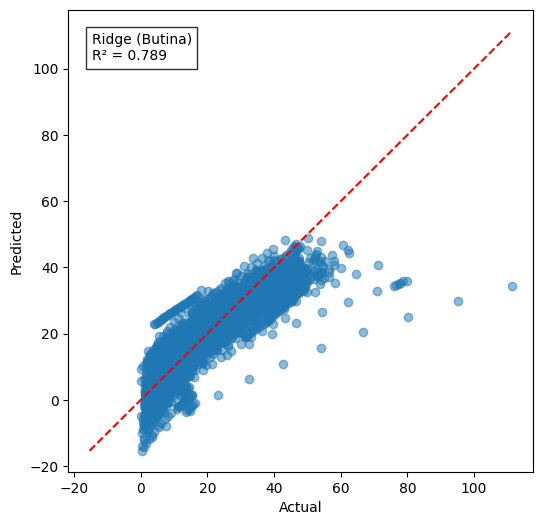

--- Ridge | Family split ---
best params: {'ridge__alpha': np.float64(0.001079276454867846), 'ridge__fit_intercept': True}
CV metrics per fold - Ridge (Family)


,n_val,RMSE,MAE,r2
1,3426.0,9.199,4.888,0.563
2,3421.0,5.450,3.872,0.757
3,3426.0,5.140,3.654,0.775
4,3410.0,5.326,3.885,0.762
5,3418.0,5.998,3.763,0.750
mean,NaN,6.222,4.012,0.721
std,NaN,1.694,0.498,0.089


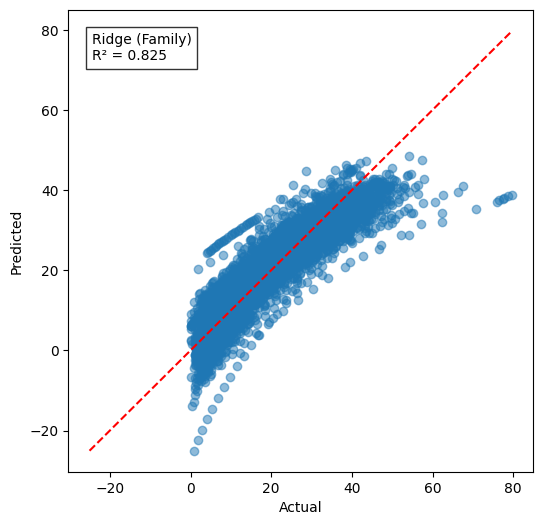

In [14]:
from sklearn.linear_model import Ridge

reg = make_pipeline(StandardScaler(), Ridge())
params = {
    'ridge__alpha': loguniform(1e-3, 1e3),
    'ridge__fit_intercept': [True, False],
}
fit_all('Ridge', reg, params)

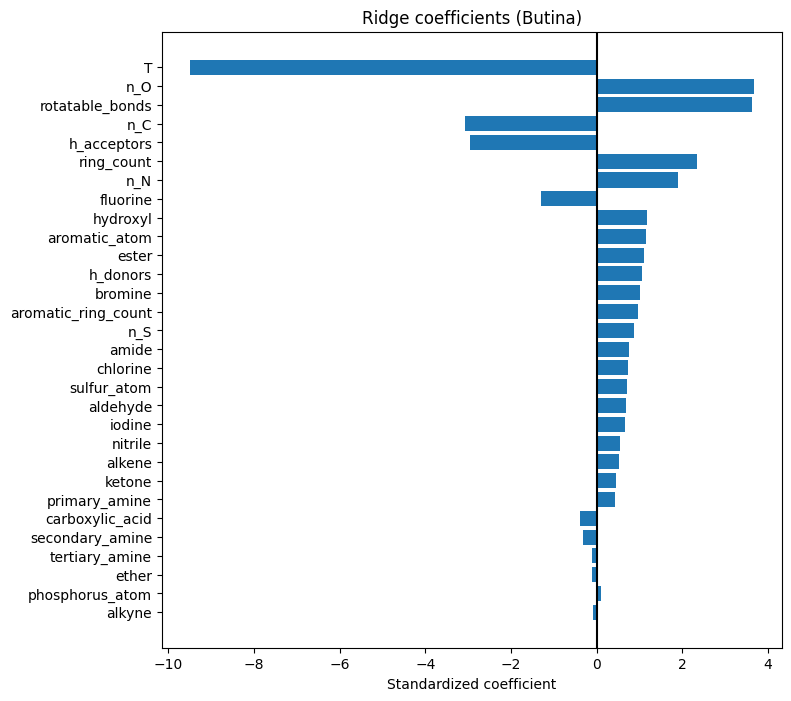

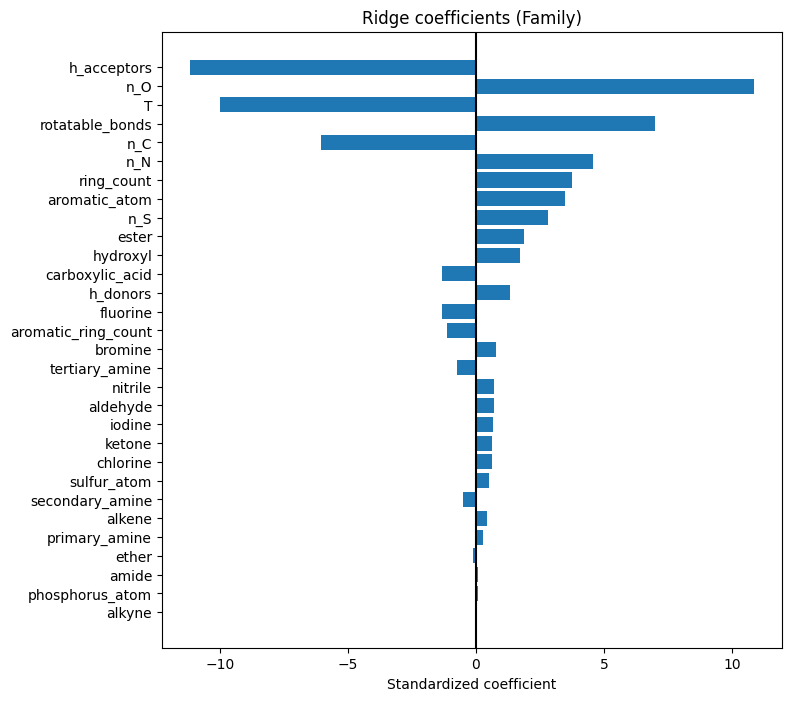

In [15]:
for s in SPLITS:
    plot_coefs('Ridge', s, 'Ridge coefficients')

### SVR

--- SVR | Butina split ---
best params: {'regressor__svr__C': np.float64(624.5139574743067), 'regressor__svr__epsilon': np.float64(0.24659691172104828), 'regressor__svr__gamma': np.float64(0.17123375973163968)}
CV metrics per fold - SVR (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.610,2.927,0.810
2,3410.0,5.380,3.460,0.741
3,3419.0,7.142,3.699,0.609
4,3410.0,4.666,3.019,0.879
5,3409.0,5.550,3.361,0.782
mean,NaN,5.470,3.293,0.764
std,NaN,1.024,0.319,0.100


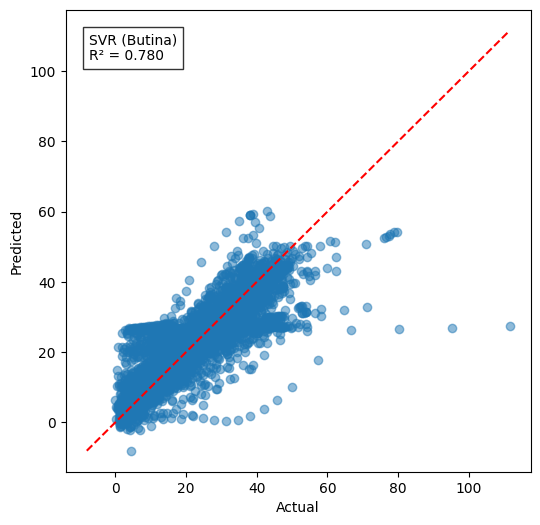

--- SVR | Family split ---
best params: {'regressor__svr__C': np.float64(624.5139574743067), 'regressor__svr__epsilon': np.float64(0.24659691172104828), 'regressor__svr__gamma': np.float64(0.17123375973163968)}
CV metrics per fold - SVR (Family)


,n_val,RMSE,MAE,r2
1,3426.0,6.276,3.478,0.796
2,3421.0,5.072,3.053,0.789
3,3426.0,5.201,3.005,0.770
4,3410.0,4.845,3.107,0.803
5,3418.0,4.813,3.068,0.839
mean,NaN,5.241,3.142,0.799
std,NaN,0.600,0.191,0.025


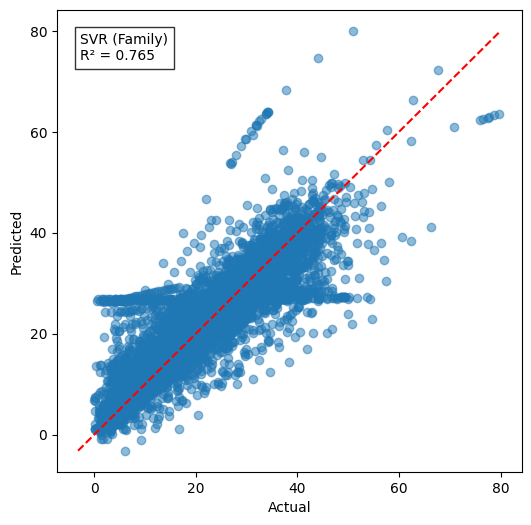

In [16]:
from sklearn.svm import SVR

reg = scaled(SVR(kernel='rbf'))
params = {
    'regressor__svr__C': loguniform(1e-1, 1e3),
    'regressor__svr__epsilon': loguniform(1e-3, 3e-1),    # in standardized-y units
    'regressor__svr__gamma': loguniform(1e-4, 1e0),
}
fit_all('SVR', reg, params, n_iter=20)

### Decision Tree

--- DecisionTree | Butina split ---
best params: {'max_depth': 20, 'min_samples_leaf': 6, 'min_samples_split': 3}
CV metrics per fold - DecisionTree (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,5.139,3.262,0.763
2,3410.0,5.280,3.406,0.750
3,3419.0,5.801,3.483,0.742
4,3410.0,4.945,3.180,0.864
5,3409.0,6.214,3.821,0.727
mean,NaN,5.476,3.430,0.769
std,NaN,0.520,0.248,0.054


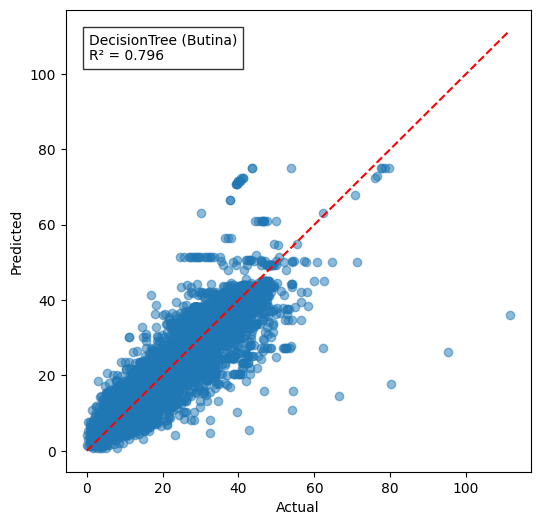

--- DecisionTree | Family split ---
best params: {'max_depth': 20, 'min_samples_leaf': 6, 'min_samples_split': 3}
CV metrics per fold - DecisionTree (Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.802,3.109,0.881
2,3421.0,6.184,3.683,0.687
3,3426.0,5.252,3.206,0.765
4,3410.0,4.752,3.114,0.810
5,3418.0,4.970,3.329,0.828
mean,NaN,5.192,3.288,0.794
std,NaN,0.588,0.238,0.073


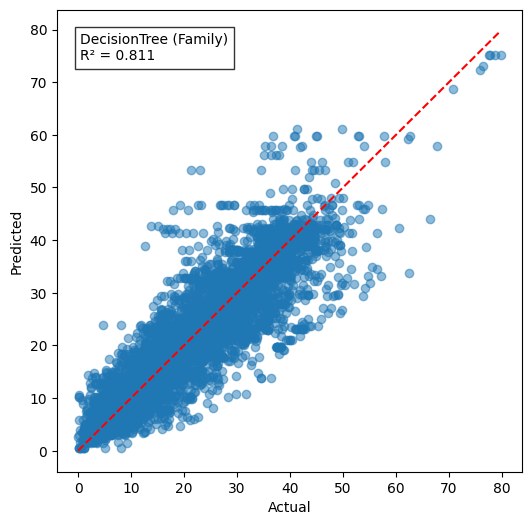

In [17]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

reg = DecisionTreeRegressor(random_state=42)
params = {
    'max_depth': [3, 6, 9, 12, 15, 20],
    'min_samples_leaf': randint(1, 30),
    'min_samples_split': randint(2, 30),
}
fit_all('DecisionTree', reg, params)

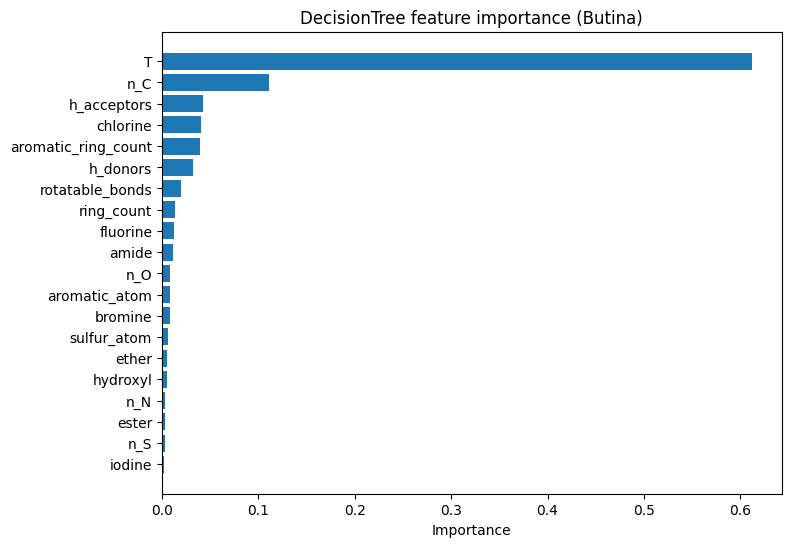

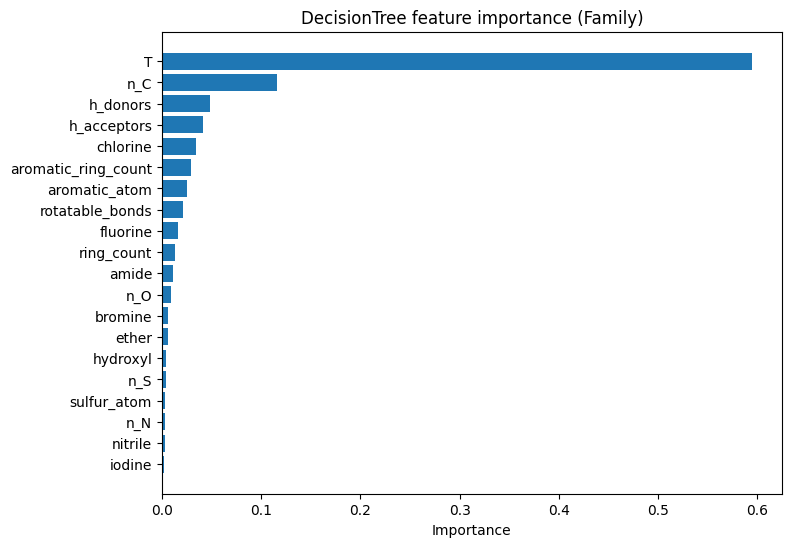

In [18]:
for s in SPLITS:
    plot_importance('DecisionTree', s)

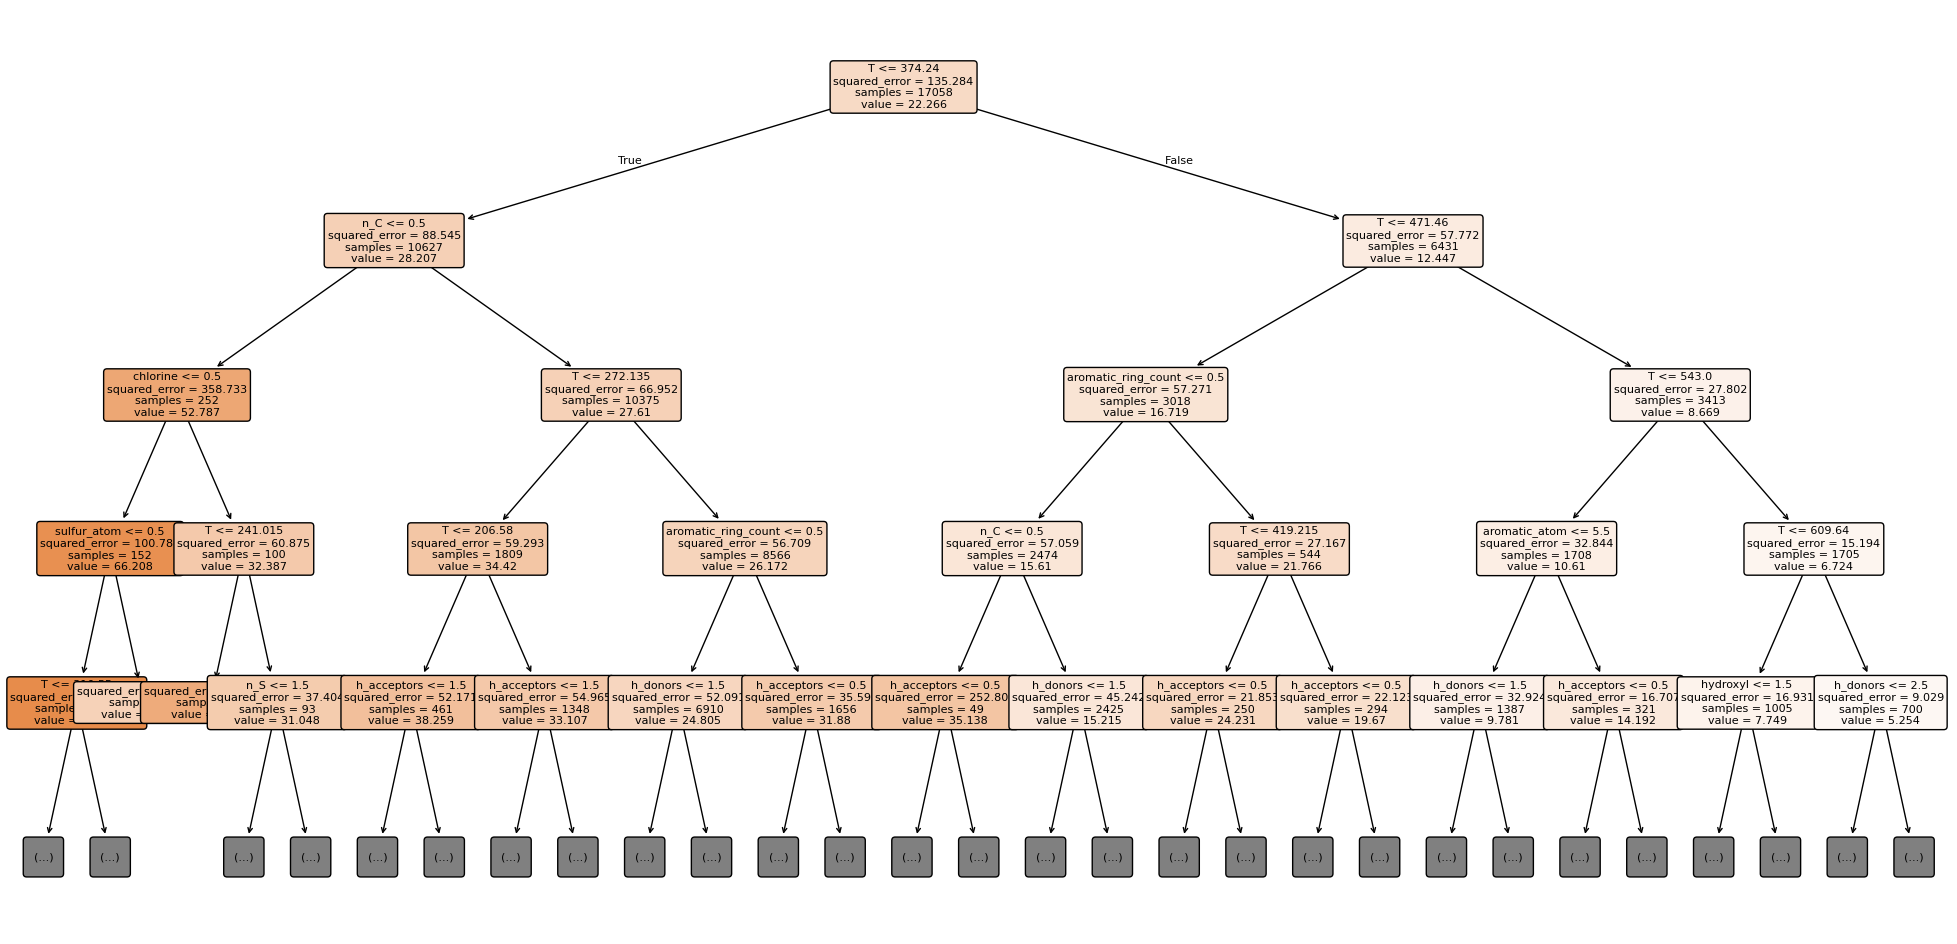

In [19]:
# tree structure (Butina split)
plt.figure(figsize=(25, 12))
plot_tree(models[('DecisionTree', 'Butina')], feature_names=group_cols, max_depth=4,
          filled=True, rounded=True, fontsize=8)
plt.show()

### Random Forest

--- RandomForest | Butina split ---
best params: {'max_depth': None, 'max_features': np.float64(0.61534947637868), 'min_samples_leaf': 2, 'n_estimators': 487}
CV metrics per fold - RandomForest (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.878,2.398,0.865
2,3410.0,4.170,2.627,0.844
3,3419.0,4.828,2.774,0.821
4,3410.0,4.337,2.621,0.895
5,3409.0,4.468,2.768,0.859
mean,NaN,4.336,2.638,0.857
std,NaN,0.353,0.153,0.027


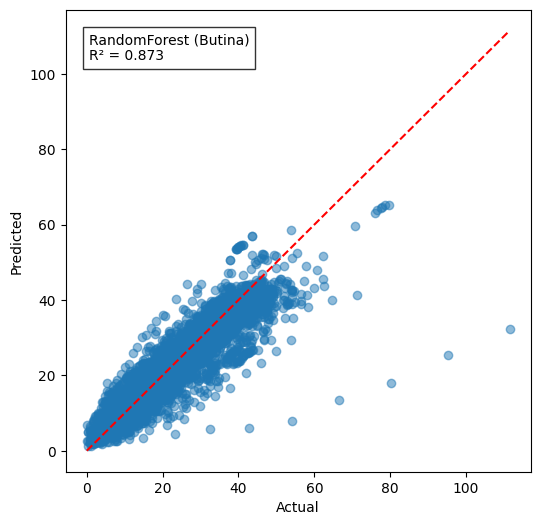

--- RandomForest | Family split ---
best params: {'max_depth': None, 'max_features': np.float64(0.61534947637868), 'min_samples_leaf': 2, 'n_estimators': 487}
CV metrics per fold - RandomForest (Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.159,2.455,0.911
2,3421.0,5.142,2.955,0.783
3,3426.0,4.328,2.477,0.841
4,3410.0,3.987,2.520,0.867
5,3418.0,4.500,2.831,0.859
mean,NaN,4.423,2.647,0.852
std,NaN,0.445,0.229,0.046


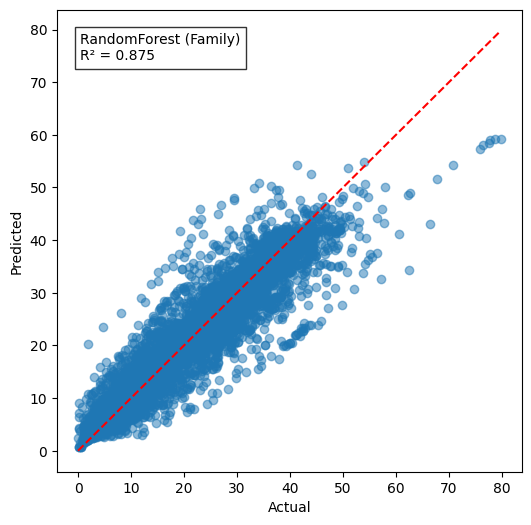

In [20]:
from sklearn.ensemble import RandomForestRegressor

reg = RandomForestRegressor(random_state=42, n_jobs=1)
params = {
    'n_estimators': randint(100, 500),
    'max_depth': [6, 9, 12, 15, None],
    'min_samples_leaf': randint(1, 10),
    'max_features': uniform(0.3, 0.7),
}
fit_all('RandomForest', reg, params, n_iter=20)

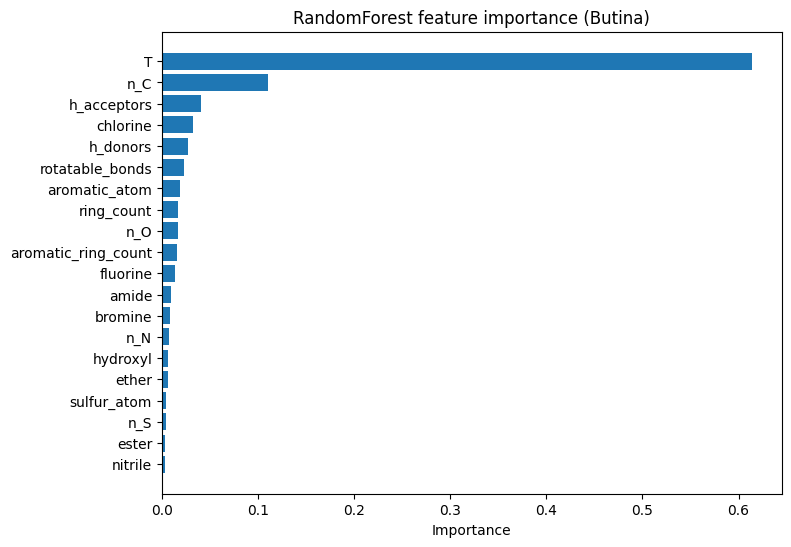

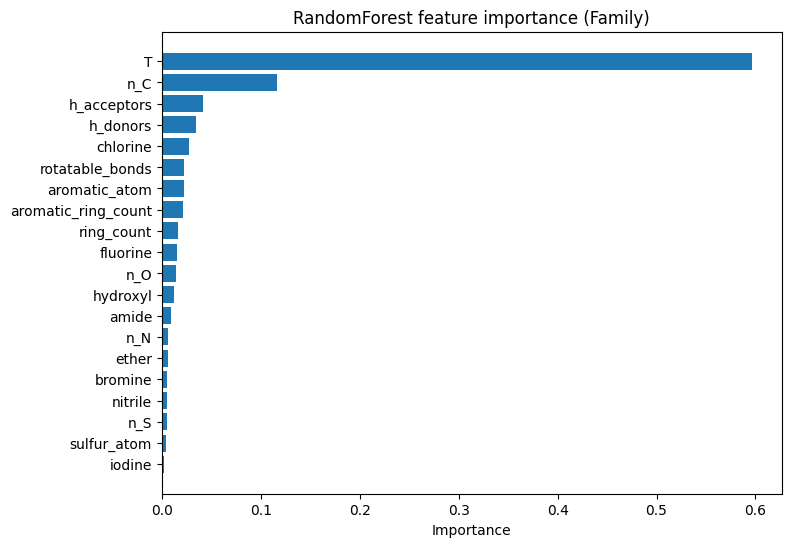

In [21]:
for s in SPLITS:
    plot_importance('RandomForest', s)

### Gaussian Process Regressor

Exact GPR scales as O(n³) in memory and time, so it cannot be tuned with CV on ~17k points. It is trained on a random subsample of the training set; the kernel hyperparameters are optimized by marginal likelihood.

Butina 1.75**2 * RBF(length_scale=2) + WhiteKernel(noise_level=0.0179)


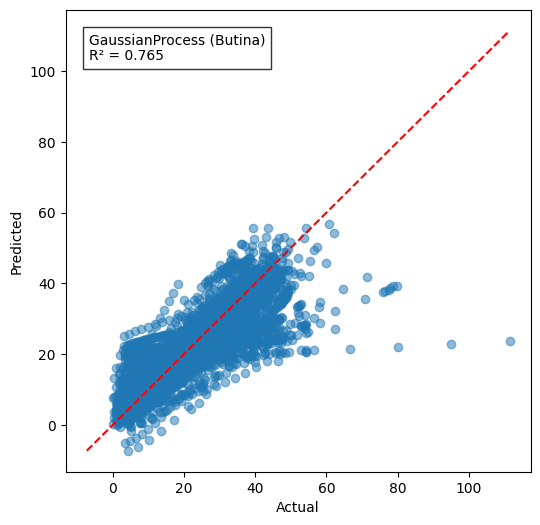

Family 1.78**2 * RBF(length_scale=2.38) + WhiteKernel(noise_level=0.0134)


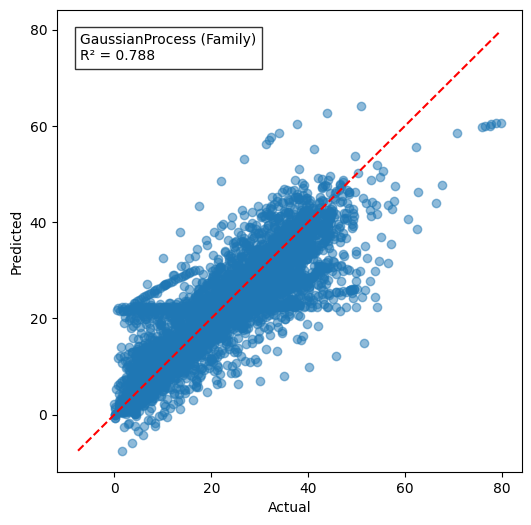

In [22]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

N_GPR = 2000
kernel = ConstantKernel(1.0) * RBF(length_scale=5.0) + WhiteKernel(noise_level=0.1)
reg = make_pipeline(StandardScaler(),
                    GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                             n_restarts_optimizer=2, random_state=42))

for s in SPLITS:
    d = data[s]
    pos = np.random.default_rng(42).choice(len(d['X_train']), size=min(N_GPR, len(d['X_train'])), replace=False)
    gpr = clone(reg).fit(d['X_train'].iloc[pos], d['y_train'].iloc[pos])
    print(s, gpr[-1].kernel_)
    record(gpr, 'GaussianProcess', s)
    plot_actual_vs_predicted(gpr, d['X_test'], d['y_test'], f'GaussianProcess ({s})')

### Gradient Boosting Regressor

--- GradientBoosting | Butina split ---
best params: {'learning_rate': np.float64(0.22038218939289875), 'loss': 'huber', 'max_depth': 3, 'n_estimators': 459, 'subsample': np.float64(0.902144564127061)}
CV metrics per fold - GradientBoosting (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.994,2.403,0.857
2,3410.0,4.191,2.476,0.843
3,3419.0,4.446,2.687,0.849
4,3410.0,3.983,2.578,0.912
5,3409.0,4.121,2.564,0.880
mean,NaN,4.147,2.542,0.868
std,NaN,0.189,0.108,0.028


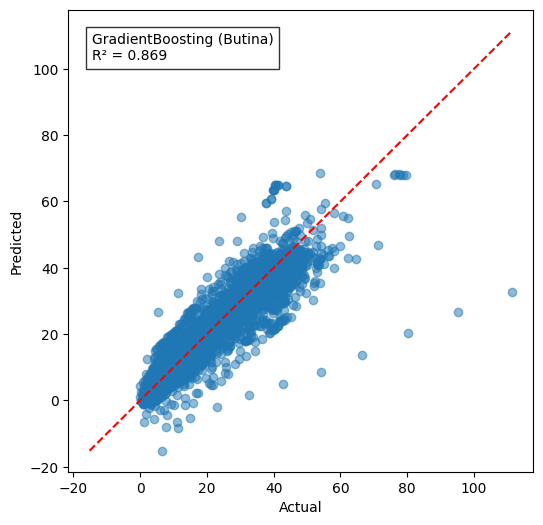

--- GradientBoosting | Family split ---
best params: {'learning_rate': np.float64(0.08167611317882542), 'loss': 'huber', 'max_depth': 7, 'n_estimators': 352, 'subsample': np.float64(0.7727780074568463)}
CV metrics per fold - GradientBoosting (Family)


,n_val,RMSE,MAE,r2
1,3426.0,3.768,2.334,0.927
2,3421.0,4.367,2.519,0.844
3,3426.0,4.327,2.394,0.841
4,3410.0,4.332,2.431,0.842
5,3418.0,4.183,2.624,0.878
mean,NaN,4.196,2.460,0.866
std,NaN,0.249,0.113,0.037


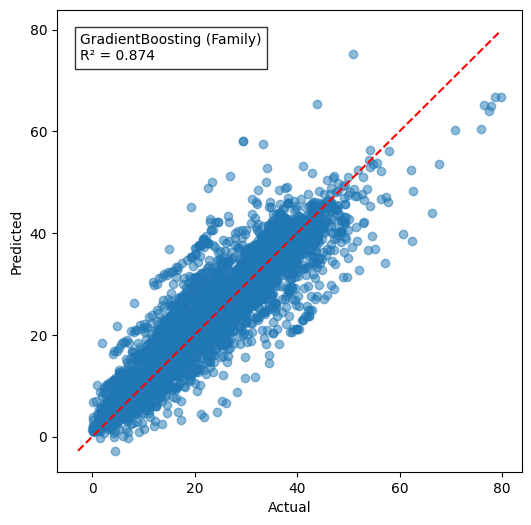

In [23]:
from sklearn.ensemble import GradientBoostingRegressor

reg = GradientBoostingRegressor(random_state=42)
params = {
    'n_estimators': randint(100, 500),
    'learning_rate': loguniform(1e-2, 3e-1),
    'max_depth': randint(2, 8),
    'subsample': uniform(0.6, 0.4),
    'loss': ['squared_error', 'huber'],
}
fit_all('GradientBoosting', reg, params, n_iter=20)

### XGBoost

--- XGBoost | Butina split ---
best params: {'colsample_bytree': np.float64(0.6002081507981263), 'learning_rate': np.float64(0.112244968336909), 'max_depth': 4, 'min_child_weight': 7, 'n_estimators': 809, 'reg_alpha': np.float64(1.0214946051551315), 'reg_lambda': np.float64(1.752233009446337), 'subsample': np.float64(0.6888431241882921)}
CV metrics per fold - XGBoost (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.981,2.364,0.858
2,3410.0,3.852,2.384,0.867
3,3419.0,4.206,2.593,0.864
4,3410.0,3.942,2.395,0.914
5,3409.0,4.095,2.485,0.881
mean,NaN,4.015,2.444,0.877
std,NaN,0.138,0.095,0.022


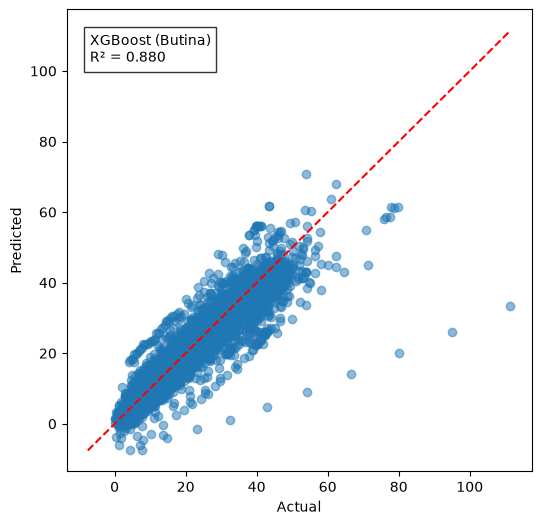

--- XGBoost | Family split ---
best params: {'colsample_bytree': np.float64(0.6431565707973218), 'learning_rate': np.float64(0.019114463849152934), 'max_depth': 8, 'min_child_weight': 1, 'n_estimators': 663, 'reg_alpha': np.float64(1.1265511439527673), 'reg_lambda': np.float64(2.5865482592783824), 'subsample': np.float64(0.6557325817623503)}
CV metrics per fold - XGBoost (Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.022,2.396,0.916
2,3421.0,4.278,2.496,0.850
3,3426.0,4.218,2.354,0.849
4,3410.0,3.963,2.343,0.868
5,3418.0,4.208,2.635,0.877
mean,NaN,4.138,2.445,0.872
std,NaN,0.137,0.122,0.028


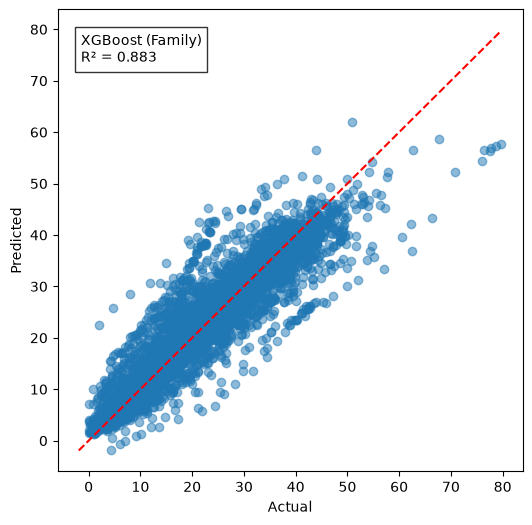

In [5]:
from xgboost import XGBRegressor

reg = XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=1)
params = {
    'n_estimators': randint(100, 1000),
    'max_depth': randint(2, 10),
    'learning_rate': uniform(0.01, 0.29),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_weight': randint(1, 10),
    'reg_alpha': uniform(0, 2),
    'reg_lambda': uniform(0.5, 3),
}
fit_all('XGBoost', reg, params)

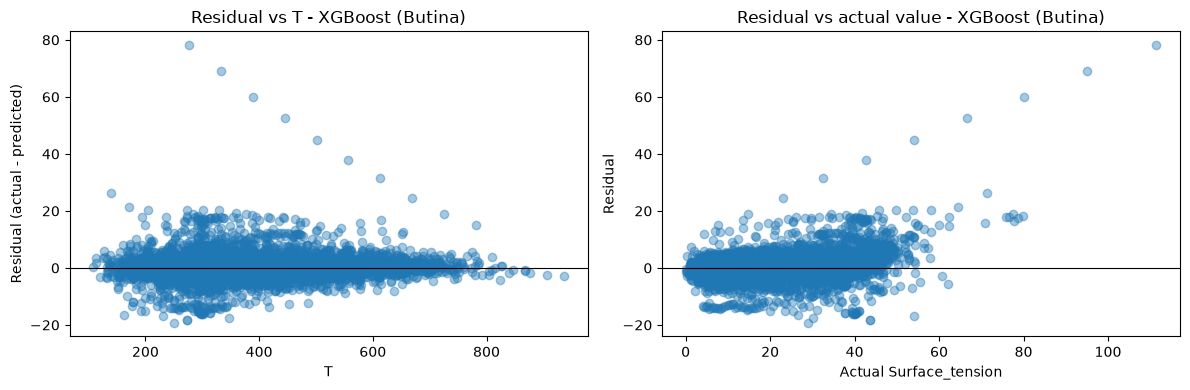

Error by Family (worst first) - XGBoost (Butina)


,n,RMSE,MAE,mean_actual,NRMSE_%,WAPE_%
Family,,,,,,
OTHER POLYFUNCTIONAL ORGANICS,10,47.848,43.282,52.842,90.550,81.909
"C, H, MULTIHALOGEN COMPOUNDS",111,7.839,5.849,14.757,53.122,39.635
"POLYFUNCTIONAL C, H, O, S",111,11.029,9.132,29.196,37.775,31.277
SILANES/SILOXANES,305,6.607,5.143,19.046,34.687,27.001
INORGANIC ACIDS,46,11.380,9.884,36.299,31.350,27.229
...,...,...,...,...,...,...
ALKYLCYCLOHEXANES,123,0.746,0.587,22.807,3.273,2.575
N-ALCOHOLS,131,0.828,0.714,25.338,3.269,2.819
N-ALKANES,89,0.582,0.488,20.185,2.883,2.416


15 worst predictions by absolute error - XGBoost (Butina)


,ChemID,Family,T,actual,predicted,residual,abs_residual,abs_pct_error
2602,1275,OTHER ALIPHATIC ACIDS,694.00,0.000,0.231000,-0.231,0.231,inf
3862,5892,"POLYFUNCTIONAL C, H, O, N",589.00,0.092,1.362000,-1.270,1.270,1382.751
2557,2801,ISOCYANATES/DIISOCYANATES,765.00,0.398,-3.864000,4.262,4.262,1072.033
4896,23340,GLYCERIDES,936.25,0.423,3.403000,-2.980,2.980,704.517
1424,2628,"C, H, F COMPOUNDS",442.89,0.203,1.519000,-1.317,1.317,650.137
3828,2996,ORGANIC SALTS,650.84,1.166,-6.065000,7.231,7.231,620.231
4299,1938,SULFIDES/THIOPHENES,519.17,2.192,10.361000,-8.169,8.169,372.656
4401,1354,AROMATIC ESTERS,804.90,0.722,3.186000,-2.464,2.464,341.266
1489,3603,"C, H, MULTIHALOGEN COMPOUNDS",344.20,4.141,17.514000,-13.373,13.373,322.935
4487,1229,POLYOLS,662.61,1.226,5.154000,-3.928,3.928,320.526


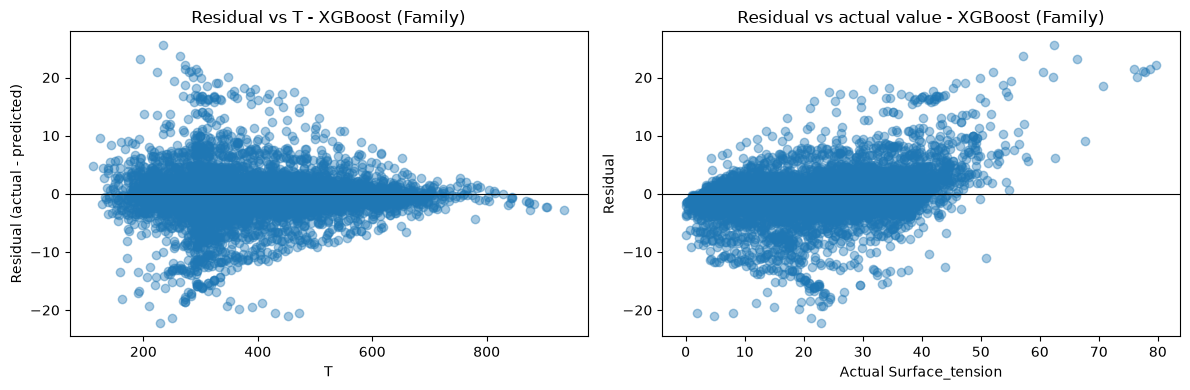

Error by Family (worst first) - XGBoost (Family)


,n,RMSE,MAE,mean_actual,NRMSE_%,WAPE_%
Family,,,,,,
INORGANIC GASES,13,18.323,18.206,20.010,91.567,90.981
"C, H, MULTIHALOGEN COMPOUNDS",104,8.661,7.994,15.692,55.192,50.941
"POLYFUNCTIONAL C, H, N, HALIDE, (O)",30,9.760,7.854,19.859,49.147,39.547
"POLYFUNCTIONAL C, H, O, S",57,12.814,11.092,28.345,45.206,39.133
N-ALCOHOLS,101,9.116,6.322,21.186,43.026,29.839
...,...,...,...,...,...,...
METHYLALKANES,107,0.745,0.639,16.998,4.383,3.760
OTHER ALKENES,16,0.764,0.634,21.962,3.481,2.885
PROPIONATES AND BUTYRATES,85,0.736,0.474,21.943,3.353,2.159


15 worst predictions by absolute error - XGBoost (Family)


,ChemID,Family,T,actual,predicted,residual,abs_residual,abs_pct_error
2763,1275,OTHER ALIPHATIC ACIDS,694.00,0.000,1.578000,-1.578,1.578,inf
3966,5892,"POLYFUNCTIONAL C, H, O, N",589.00,0.092,7.115000,-7.023,7.023,7645.782
3960,6851,ORGANIC/INORGANIC COMPOUNDS,681.70,0.120,3.991000,-3.871,3.871,3231.406
2775,3898,ORGANIC/INORGANIC COMPOUNDS,675.63,0.118,3.605000,-3.486,3.486,2947.542
5227,1032,ALDEHYDES,543.20,0.097,2.111000,-2.014,2.014,2076.184
1436,2628,"C, H, F COMPOUNDS",442.89,0.203,3.891000,-3.688,3.688,1820.866
1397,911,INORGANIC GASES,472.01,1.934,22.478001,-20.544,20.544,1062.280
1577,1101,N-ALCOHOLS,503.15,0.900,10.025000,-9.125,9.125,1013.918
2748,1435,"OTHER POLYFUNCTIONAL C, H, O",712.80,0.340,3.018000,-2.678,2.678,787.582
8184,2649,"C, H, MULTIHALOGEN COMPOUNDS",462.65,0.814,7.037000,-6.223,6.223,764.479


In [10]:
for s in SPLITS:
    diagnose_errors('XGBoost', s)

In [11]:
for s in SPLITS:
    check_tc_violations('XGBoost', s)

Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - XGBoost (Butina)


,T/TC >=,n_rows,n_violations
0,0.90,217,152
1,0.95,44,13
2,0.98,5,0
3,0.99,4,0


15 worst violations (closest to TC, by T/TC) - XGBoost (Butina)


,ChemID,Family,T,TC,actual,predicted,Tr
4896,23340,GLYCERIDES,936.25,966.40,0.423,3.403,0.969
4730,1378,AROMATIC ESTERS,839.64,870.00,0.947,2.657,0.965
4346,9899,POLYFUNCTIONAL ESTERS,823.03,853.90,1.331,5.415,0.964
8166,2649,"C, H, MULTIHALOGEN COMPOUNDS",462.65,481.00,0.814,2.981,0.962
4918,21381,AROMATIC ESTERS,747.98,779.00,1.964,2.245,0.960
4660,9866,"POLYFUNCTIONAL C, H, O, N",705.83,736.00,1.669,6.212,0.959
4401,1354,AROMATIC ESTERS,804.90,840.00,0.722,3.186,0.958
1423,2628,"C, H, F COMPOUNDS",432.35,451.55,0.915,2.301,0.957
4153,1792,AROMATIC AMINES,673.52,705.00,1.614,2.718,0.955
4327,3119,AROMATIC ALCOHOLS,668.60,700.00,1.550,2.147,0.955


Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - XGBoost (Family)


,T/TC >=,n_rows,n_violations
0,0.90,217,200
1,0.95,44,39
2,0.98,8,7
3,0.99,5,4


15 worst violations (closest to TC, by T/TC) - XGBoost (Family)


,ChemID,Family,T,TC,actual,predicted,Tr
5227,1032,ALDEHYDES,543.20,543.20,0.097,2.111,1.000
3960,6851,ORGANIC/INORGANIC COMPOUNDS,681.70,682.00,0.120,3.991,1.000
2775,3898,ORGANIC/INORGANIC COMPOUNDS,675.63,676.00,0.118,3.605,0.999
3966,5892,"POLYFUNCTIONAL C, H, O, N",589.00,590.00,0.092,7.115,0.998
2748,1435,"OTHER POLYFUNCTIONAL C, H, O",712.80,720.00,0.340,3.018,0.990
1436,2628,"C, H, F COMPOUNDS",442.89,451.55,0.203,3.891,0.981
1577,1101,N-ALCOHOLS,503.15,513.20,0.900,10.025,0.980
5084,23338,GLYCERIDES,935.07,965.40,0.431,3.303,0.969
4761,3340,GLYCERIDES,903.77,933.80,0.781,3.126,0.968
2747,1435,"OTHER POLYFUNCTIONAL C, H, O",696.67,720.00,1.190,3.018,0.968


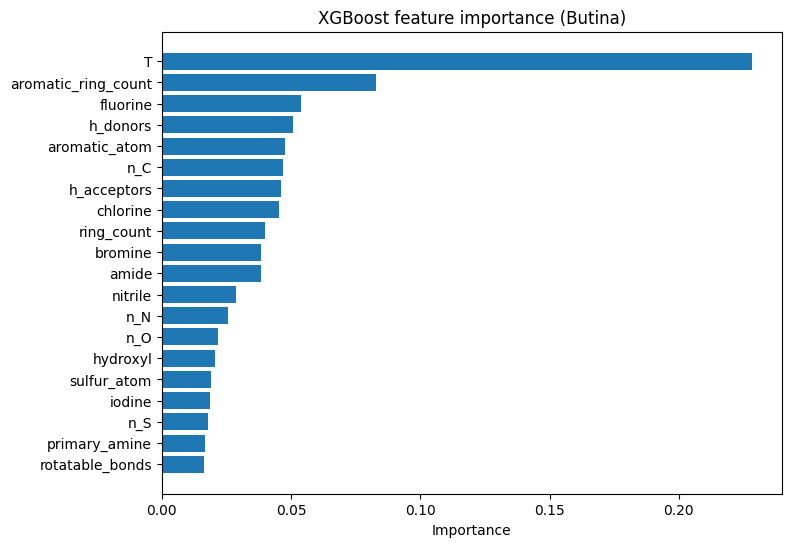

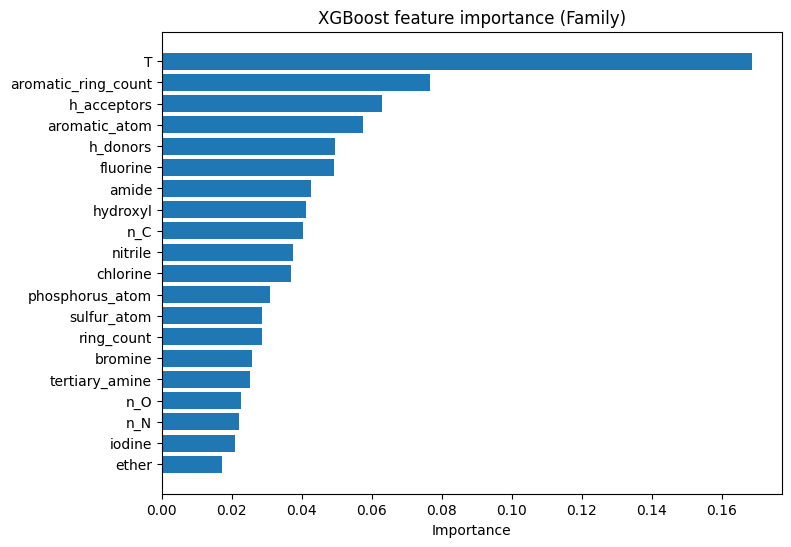

In [25]:
for s in SPLITS:
    plot_importance('XGBoost', s)

### Multilayer perceptron

--- MLP | Butina split ---
best params: {'regressor__mlpregressor__activation': 'relu', 'regressor__mlpregressor__alpha': np.float64(0.02339586455122246), 'regressor__mlpregressor__hidden_layer_sizes': (100, 50), 'regressor__mlpregressor__learning_rate_init': np.float64(0.007568292060167619)}
CV metrics per fold - MLP (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.810,2.180,0.870
2,3410.0,3.814,2.295,0.870
3,3419.0,5.790,2.937,0.743
4,3410.0,3.954,2.281,0.913
5,3409.0,4.540,2.709,0.854
mean,NaN,4.382,2.481,0.850
std,NaN,0.843,0.326,0.064


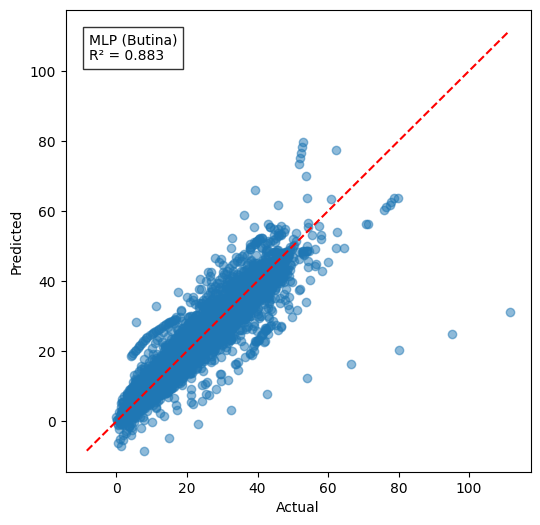

--- MLP | Family split ---
best params: {'regressor__mlpregressor__activation': 'relu', 'regressor__mlpregressor__alpha': np.float64(0.02339586455122246), 'regressor__mlpregressor__hidden_layer_sizes': (100, 50), 'regressor__mlpregressor__learning_rate_init': np.float64(0.007568292060167619)}
CV metrics per fold - MLP (Family)


,n_val,RMSE,MAE,r2
1,3426.0,6.007,2.827,0.814
2,3421.0,3.833,2.341,0.880
3,3426.0,4.343,2.199,0.839
4,3410.0,3.637,2.136,0.889
5,3418.0,3.737,2.240,0.903
mean,NaN,4.311,2.349,0.865
std,NaN,0.986,0.278,0.037


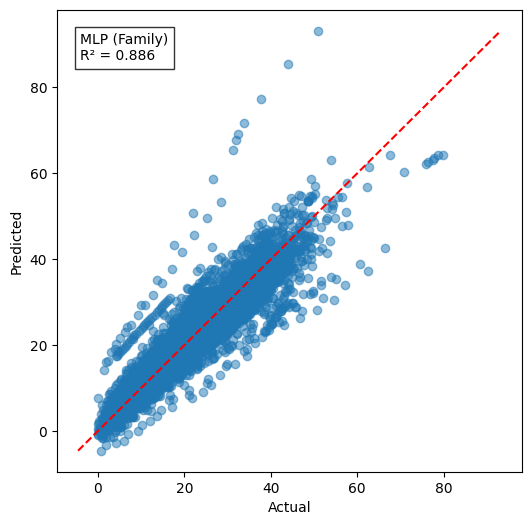

In [26]:
from sklearn.neural_network import MLPRegressor

reg = scaled(MLPRegressor(max_iter=2000, early_stopping=True, n_iter_no_change=20, random_state=42))
params = {
    'regressor__mlpregressor__hidden_layer_sizes': [(50,), (100,), (50, 25), (100, 50), (50, 25, 10)],
    'regressor__mlpregressor__activation': ['relu', 'tanh'],
    'regressor__mlpregressor__alpha': loguniform(1e-5, 1e-1),
    'regressor__mlpregressor__learning_rate_init': loguniform(1e-4, 1e-2),
}
fit_all('MLP', reg, params, n_iter=20)

### Multilayer Perceptron (PyTorch)

A from-scratch feedforward network (`TorchMLPRegressor` below) instead of `sklearn`'s `MLPRegressor`, giving explicit control over the regularization asked for:
- **Batch normalization** after every hidden `Linear` layer
- **Dropout** after each batch-norm/activation
- **Weight decay** (L2 penalty), via `Adam`'s `weight_decay`
- **Early stopping** on a held-out validation slice carved out of each fit's training data, restoring the best-validation-loss weights at the end of training, plotted below as loss and R² vs epoch (train and validation, with the best epoch marked)

It's wrapped as a scikit-learn estimator (`BaseEstimator`/`RegressorMixin`), so it plugs into the same `scaled(...)` / `fit_all(...)` machinery as the other models and lands in the same `metrics_<split>.pkl` tables for direct comparison, as `MLP_PyTorch` next to the existing sklearn `MLP`.

Caveats:
- The early-stopping validation slice is a plain random split, **not** grouped by `ChemID` like the outer CV/test splits - a practical simplification. It can share compounds with the rest of that fit's training data, so it's only meant to catch overfitting within a single fit, not to give a leakage-free estimate.

In [12]:
!pip install torch

   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.1/126.7 MB 1.3 MB/s eta 0:01:37
   ---------------------------------------- 0.2/126.7 MB 2.6 MB/s eta 0:00:49
   ---------------------------------------- 0.5/126.7 MB 3.5 MB/s eta 0:00:36
   ---------------------------------------- 1.2/126.7 MB 6.2 MB/s eta 0:00:21
    --------------------------------------- 2.5/126.7 MB 10.8 MB/s eta 0:00:12
   - -------------------------------------- 3.9/126.7 MB 13.7 MB/s eta 0:00:09
   - -------------------------------------- 5.0/126.7 MB 14.6 MB/s eta 0:00:09
   - -------------------------------------- 6.2/126.7 MB 16.4 MB/s eta 0:00:08
   -- ------------------------------------- 7.0/126.7 MB 16.5 MB/s eta 0:00:08
   -- ------------------------------------- 8.1/126.7 MB 17.3 MB/s eta 0:00:07
   -- ------------------------------------- 9.2/126.7 MB 17.8 MB/s eta 0:00:07
   --- ------------------------------------ 10.2/126.7 MB 18.2 M


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


--- MLP_PyTorch | Butina split ---
best params: {'regressor__torchmlpregressor__dropout': np.float64(0.23338144662398996), 'regressor__torchmlpregressor__hidden_layer_sizes': (128, 64, 32), 'regressor__torchmlpregressor__lr': np.float64(0.0016409286730647919), 'regressor__torchmlpregressor__weight_decay': np.float64(4.809461967501575e-06)}
CV metrics per fold - MLP_PyTorch (Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.399,2.205,0.896
2,3410.0,3.487,2.303,0.891
3,3419.0,6.252,2.896,0.701
4,3410.0,3.160,2.112,0.944
5,3409.0,4.387,2.606,0.864
mean,NaN,4.137,2.424,0.859
std,NaN,1.271,0.322,0.093


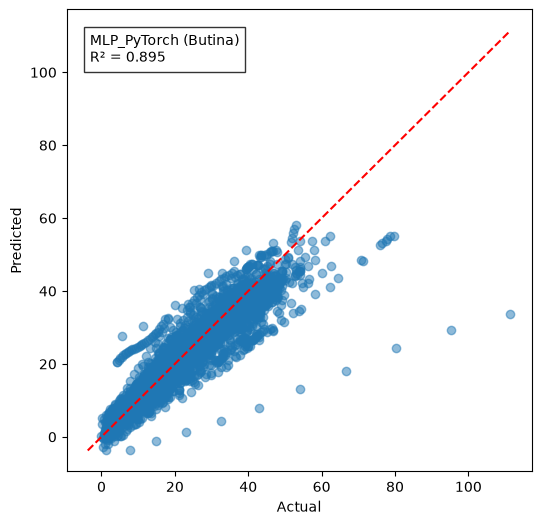

--- MLP_PyTorch | Family split ---
best params: {'regressor__torchmlpregressor__dropout': np.float64(0.028205789513550128), 'regressor__torchmlpregressor__hidden_layer_sizes': (128, 64), 'regressor__torchmlpregressor__lr': np.float64(0.007535384509295544), 'regressor__torchmlpregressor__weight_decay': np.float64(1.0071984838809197e-06)}
CV metrics per fold - MLP_PyTorch (Family)


,n_val,RMSE,MAE,r2
1,3426.0,5.474,2.541,0.845
2,3421.0,4.420,2.556,0.840
3,3426.0,4.111,2.121,0.856
4,3410.0,3.345,2.069,0.906
5,3418.0,3.632,2.215,0.908
mean,NaN,4.196,2.301,0.871
std,NaN,0.827,0.233,0.033


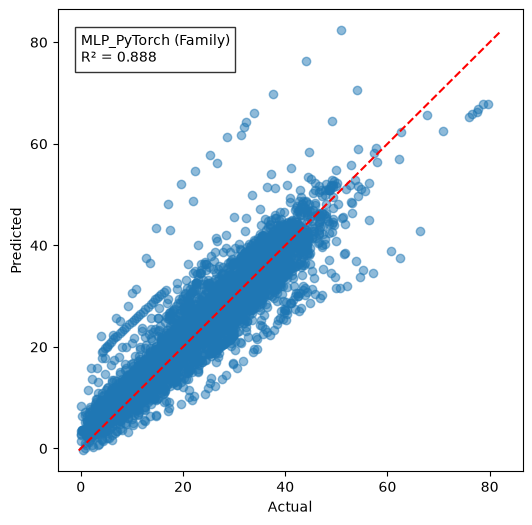

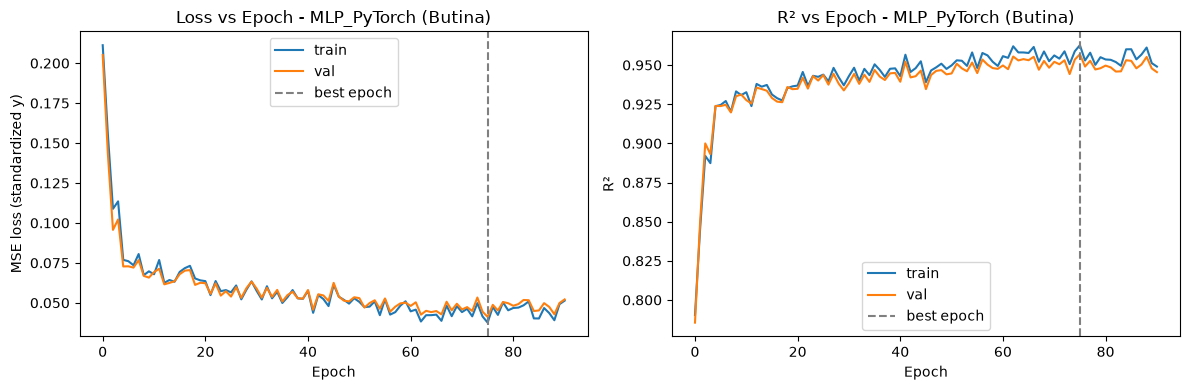

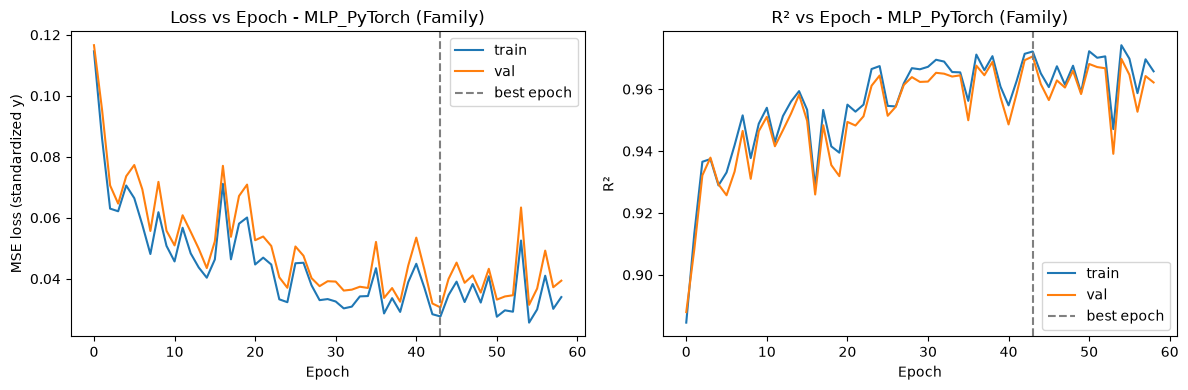

In [14]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.utils.validation import check_is_fitted


class TorchMLPRegressor(BaseEstimator, RegressorMixin):
    """[Linear -> BatchNorm -> ReLU -> Dropout] per hidden layer, then a linear output.
    Trained with Adam (weight_decay = L2) and early stopping on a held-out validation slice."""

    def __init__(self, hidden_layer_sizes=(64, 32), dropout=0.2, weight_decay=1e-4, lr=1e-3,
                 batch_size=64, max_epochs=200, patience=15, val_size=0.15, random_state=42, device=None):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.lr = lr
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_size = val_size
        self.random_state = random_state
        self.device = device

    def _build(self, n_features):
        device = self.device or ('cuda' if torch.cuda.is_available() else 'cpu')
        layers, in_dim = [], n_features
        for h in self.hidden_layer_sizes:
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(self.dropout)]
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        return nn.Sequential(*layers).to(device), device

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32).reshape(-1, 1)

        # Held out purely for early stopping - see the caveat above about ChemID grouping.
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=self.val_size,
                                                     random_state=self.random_state)

        self.model_, self.device_ = self._build(X.shape[1])
        opt = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.MSELoss()

        X_tr_t = torch.tensor(X_tr, device=self.device_)
        y_tr_t = torch.tensor(y_tr, device=self.device_)
        X_val_t = torch.tensor(X_val, device=self.device_)
        y_val_t = torch.tensor(y_val, device=self.device_)

        rng = np.random.default_rng(self.random_state)
        best_val, best_state, best_epoch, stall, epoch = np.inf, None, 0, 0, 0
        history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'train_r2': [], 'val_r2': []}

        for epoch in range(self.max_epochs):
            self.model_.train()
            perm = rng.permutation(len(X_tr_t))
            for start in range(0, len(perm), self.batch_size):
                idx = perm[start:start + self.batch_size]
                if len(idx) < 2:
                    continue   # BatchNorm needs >=2 samples per batch in train mode
                idx_t = torch.as_tensor(idx, dtype=torch.long, device=self.device_)
                opt.zero_grad()
                loss = loss_fn(self.model_(X_tr_t[idx_t]), y_tr_t[idx_t])
                loss.backward()
                opt.step()

            # full-batch eval, for the loss/R2-vs-epoch curves and the early-stopping check
            self.model_.eval()
            with torch.no_grad():
                train_pred = self.model_(X_tr_t)
                val_pred = self.model_(X_val_t)
                train_loss = loss_fn(train_pred, y_tr_t).item()
                val_loss = loss_fn(val_pred, y_val_t).item()

            history['epoch'].append(epoch)
            history['train_loss'].append(train_loss)
            history['val_loss'].append(val_loss)
            history['train_r2'].append(r2_score(y_tr, train_pred.cpu().numpy()))
            history['val_r2'].append(r2_score(y_val, val_pred.cpu().numpy()))

            if val_loss < best_val - 1e-6:
                best_val, best_epoch, stall = val_loss, epoch, 0
                best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
            else:
                stall += 1
            if stall >= self.patience:
                break

        self.model_.load_state_dict(best_state)
        self.n_epochs_, self.best_val_loss_, self.best_epoch_ = epoch + 1, best_val, best_epoch
        self.history_ = history
        return self

    def predict(self, X):
        check_is_fitted(self, 'model_')
        X = np.asarray(X, dtype=np.float32)
        self.model_.eval()
        with torch.no_grad():
            return self.model_(torch.tensor(X, device=self.device_)).cpu().numpy().ravel()


reg = scaled(TorchMLPRegressor(max_epochs=200, patience=15))
params = {
    'regressor__torchmlpregressor__hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)],
    'regressor__torchmlpregressor__dropout': uniform(0.0, 0.5),
    'regressor__torchmlpregressor__weight_decay': loguniform(1e-6, 1e-2),
    'regressor__torchmlpregressor__lr': loguniform(1e-4, 1e-2),
}
fit_all('MLP_PyTorch', reg, params, n_iter=10, n_jobs=1)

for s in SPLITS:
    plot_training_curves('MLP_PyTorch', s, f'MLP_PyTorch ({s})')

In [15]:
for s in SPLITS:
    check_tc_violations('MLP_PyTorch', s)

Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - MLP_PyTorch (Butina)


,T/TC >=,n_rows,n_violations
0,0.90,217,164
1,0.95,44,15
2,0.98,5,3
3,0.99,4,2


15 worst violations (closest to TC, by T/TC) - MLP_PyTorch (Butina)


,ChemID,Family,T,TC,actual,predicted,Tr
3856,1035,ALDEHYDES,554.14,554.00,4.451,2.018,1.000
3862,5892,"POLYFUNCTIONAL C, H, O, N",589.00,590.00,0.092,5.241,0.998
1424,2628,"C, H, F COMPOUNDS",442.89,451.55,0.203,3.538,0.981
4523,1225,POLYOLS,779.31,809.70,1.518,4.525,0.962
8166,2649,"C, H, MULTIHALOGEN COMPOUNDS",462.65,481.00,0.814,4.985,0.962
1423,2628,"C, H, F COMPOUNDS",432.35,451.55,0.915,4.105,0.957
4187,2121,AROMATIC ALCOHOLS,700.80,732.00,1.529,2.110,0.957
4789,3910,"POLYFUNCTIONAL C, H, O, N",704.90,736.30,1.169,3.690,0.957
4451,5934,ORGANIC/INORGANIC COMPOUNDS,663.35,694.20,1.152,2.297,0.956
4327,3119,AROMATIC ALCOHOLS,668.60,700.00,1.550,3.176,0.955


Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - MLP_PyTorch (Family)


,T/TC >=,n_rows,n_violations
0,0.90,217,209
1,0.95,44,40
2,0.98,8,7
3,0.99,5,4


15 worst violations (closest to TC, by T/TC) - MLP_PyTorch (Family)


,ChemID,Family,T,TC,actual,predicted,Tr
5227,1032,ALDEHYDES,543.20,543.20,0.097,2.626,1.000
3960,6851,ORGANIC/INORGANIC COMPOUNDS,681.70,682.00,0.120,3.442,1.000
2775,3898,ORGANIC/INORGANIC COMPOUNDS,675.63,676.00,0.118,2.837,0.999
3966,5892,"POLYFUNCTIONAL C, H, O, N",589.00,590.00,0.092,8.316,0.998
2748,1435,"OTHER POLYFUNCTIONAL C, H, O",712.80,720.00,0.340,3.214,0.990
1436,2628,"C, H, F COMPOUNDS",442.89,451.55,0.203,6.490,0.981
1577,1101,N-ALCOHOLS,503.15,513.20,0.900,6.687,0.980
2747,1435,"OTHER POLYFUNCTIONAL C, H, O",696.67,720.00,1.190,4.040,0.968
4890,1380,AROMATIC ESTERS,786.48,817.00,0.989,3.436,0.963
4551,1225,POLYOLS,779.31,809.70,1.518,6.640,0.962


# Model comparison

In [30]:
# CV (mean +- std over folds, best candidate) vs test-set RMSE. GaussianProcess has no CV.
for s in SPLITS:
    rows = []
    for (alg, sp), f in cv_folds.items():
        if sp != s:
            continue
        test_rmse = metrics[s].loc[metrics[s]['algorithm'] == alg, 'RMSE'].iloc[0]
        rows.append({'algorithm': alg, 'CV_RMSE_mean': f['RMSE'].mean(), 'CV_RMSE_std': f['RMSE'].std(),
                     'CV_r2_mean': f['r2'].mean(), 'test_RMSE': test_rmse})
        
    print(f'===== {s} split: CV vs test =====')
    display(pd.DataFrame(rows).sort_values('test_RMSE').round(3).reset_index(drop=True))

===== Butina split: CV vs test =====


,algorithm,CV_RMSE_mean,CV_RMSE_std,CV_r2_mean,test_RMSE
0,MLP_PyTorch,4.099,1.291,0.863,3.343
1,XGBoost,4.015,0.138,0.877,3.483
2,GradientBoosting,4.147,0.189,0.868,3.525
3,SVR,5.470,1.024,0.764,3.623
4,MLP,4.382,0.843,0.850,3.687
5,RandomForest,4.336,0.353,0.857,3.828
6,DecisionTree,5.476,0.520,0.769,4.976
7,Ridge,6.184,2.086,0.713,5.341
8,LinearRegression,6.531,2.149,0.671,5.362


===== Family split: CV vs test =====


,algorithm,CV_RMSE_mean,CV_RMSE_std,CV_r2_mean,test_RMSE
0,XGBoost,4.138,0.137,0.872,3.560
1,RandomForest,4.423,0.445,0.852,3.627
2,MLP_PyTorch,4.341,1.318,0.863,3.756
3,GradientBoosting,4.196,0.249,0.866,3.816
4,MLP,4.311,0.986,0.865,3.914
5,SVR,5.241,0.600,0.799,4.049
6,DecisionTree,5.192,0.588,0.794,4.861
7,Ridge,6.222,1.694,0.721,5.705
8,LinearRegression,6.222,1.694,0.721,5.762


### Test-set metrics

In [29]:
for s in SPLITS:
    print(f'===== {s} split =====')
    display(metrics[s].sort_values('RMSE').reset_index(drop=True).round(3))

===== Butina split =====


,description,algorithm,MSE,RMSE,MAE,SD_error,NRMSE_%,r2_score
0,Descriptors,MLP_PyTorch,11.172621,3.342547,1.953643,3.342645,15.170166,0.911501
1,Descriptors,XGBoost,12.13212,3.483119,1.971473,3.477951,15.808154,0.903901
2,Descriptors,GradientBoosting,12.422363,3.524537,1.960977,3.516391,15.99613,0.901602
3,Descriptors,SVR,13.1236,3.622651,2.012031,3.614743,16.441419,0.896047
4,GC,MLP_PyTorch,13.226527,3.636829,2.08657,3.626986,16.505767,0.895232
5,Descriptors,MLP,13.593887,3.686989,2.004373,3.681039,16.733417,0.892322
6,Descriptors,RandomForest,14.653414,3.827978,2.17021,3.817407,17.373296,0.88393
7,GC,MLP,14.814753,3.848994,2.167495,3.840811,17.468677,0.882652
8,GC,XGBoost,15.09246,3.884902,2.237017,3.876862,17.631645,0.880452
9,GC,RandomForest,16.050737,4.006337,2.384896,3.98643,18.182781,0.872861


===== Family split =====


,description,algorithm,MSE,RMSE,MAE,SD_error,NRMSE_%,r2_score
0,GC,MLP_PyTorch,11.498182,3.390897,2.157482,3.37111,15.499867,0.90185
1,Descriptors,XGBoost,12.673114,3.559932,2.03272,3.549482,16.272529,0.89182
2,Descriptors,RandomForest,13.155799,3.627092,2.159858,3.623848,16.579522,0.8877
3,GC,MLP,13.384342,3.658462,2.181232,3.647587,16.722912,0.885749
4,GC,XGBoost,13.737128,3.706363,2.253807,3.702378,16.941871,0.882738
5,Descriptors,MLP_PyTorch,14.108286,3.7561,2.111376,3.730603,17.169218,0.879569
6,Descriptors,GradientBoosting,14.562817,3.816126,2.176133,3.801668,17.443599,0.875689
7,GC,RandomForest,14.668975,3.83001,2.420258,3.828464,17.507062,0.874783
8,GC,GradientBoosting,14.738294,3.839049,2.316814,3.833018,17.548379,0.874191
9,Descriptors,MLP,15.323083,3.914471,2.188752,3.912758,17.893136,0.8692
